In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Загрузка данных
df = pd.read_csv('titanic.csv')

Импорт библиотек

In [2]:
features = ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']
target = 'Survived'

data = df[features + [target]].copy()

Из исходного набора данных выбраны 6 признаков — Pclass, Age, Sex, Fare, SibSp, Parch. Определена целевая переменная Survived. Создана отдельная таблица data, содержащая только нужные столбцы.

In [3]:
data.isnull().sum()

,0
Pclass,0
Age,177
Sex,0
Fare,0
SibSp,0
Parch,0
Survived,0


Проверка наличия пропусков. Пропуски есть только в столбце Age (177 значений), остальные признаки заполнены полностью.

In [4]:
data['Age'] = data['Age'].fillna(data['Age'].median())

Пропуски в Age заполнены медианой. После этой операции пропусков не осталось.

In [5]:
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})

Текстовый признак Sex преобразован в числовой с помощью map. Мужчинам присвоено 0, женщинам — 1.


In [6]:
data.isnull().sum()
data.dtypes

,0
Pclass,int64
Age,float64
Sex,int64
Fare,float64
SibSp,int64
Parch,int64
Survived,int64


 Проверка на пропущенные значения и числовой формат

In [7]:
corr_data = data[['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch', 'Survived']]
corr_data.head()

,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
0,3,22.0,0,7.2500,1,0,0
1,1,38.0,1,71.2833,1,0,1
2,3,26.0,1,7.9250,0,0,1
3,1,35.0,1,53.1000,1,0,1
4,3,35.0,0,8.0500,0,0,0


Признаки объединены с целевой переменной Survived в одну таблицу corr_data.

In [8]:
corr_matrix = corr_data.corr()
corr_matrix_rounded = corr_matrix.round(2)
print(corr_matrix_rounded)

          Pclass   Age   Sex  Fare  SibSp  Parch  Survived
Pclass      1.00 -0.34 -0.13 -0.55   0.08   0.02     -0.34
Age        -0.34  1.00 -0.08  0.10  -0.23  -0.17     -0.06
Sex        -0.13 -0.08  1.00  0.18   0.11   0.25      0.54
Fare       -0.55  0.10  0.18  1.00   0.16   0.22      0.26
SibSp       0.08 -0.23  0.11  0.16   1.00   0.41     -0.04
Parch       0.02 -0.17  0.25  0.22   0.41   1.00      0.08
Survived   -0.34 -0.06  0.54  0.26  -0.04   0.08      1.00


Рассчет корреляции между всеми числовыми признаками и округлена до двух знаков после запятой

In [9]:
survived_corr = corr_matrix_rounded['Survived'].drop('Survived')
print(survived_corr.sort_values(ascending=False))

Sex       0.54
Fare      0.26
Parch     0.08
SibSp    -0.04
Age      -0.06
Pclass   -0.34
Name: Survived, dtype: float64


Найден столбец Survived, из него исключена корреляция  с самим собой, значения отсортированы.

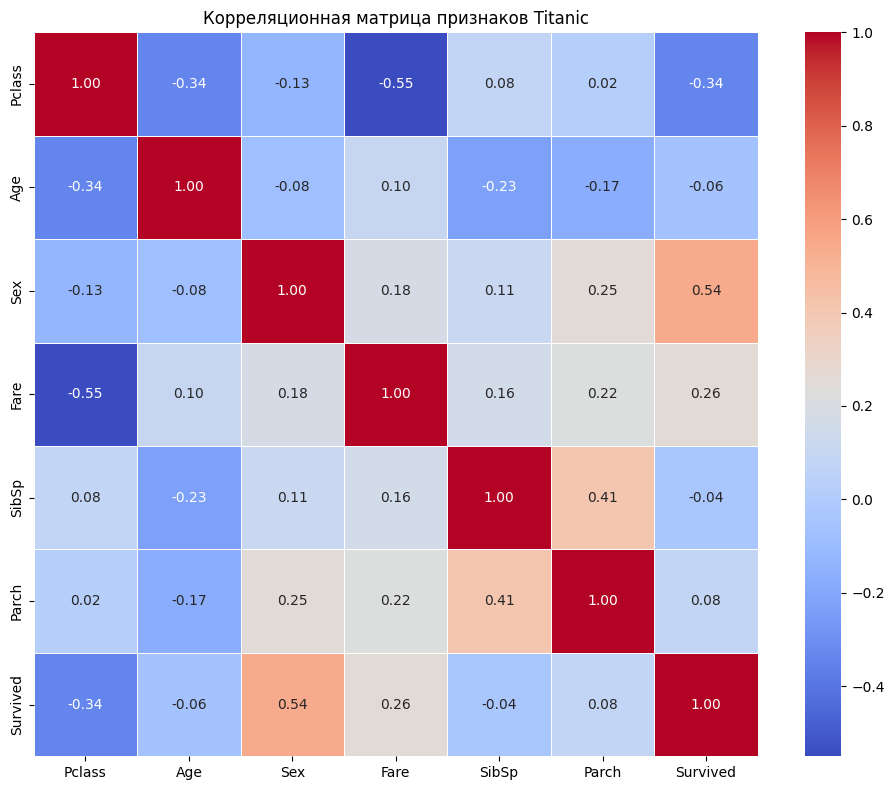

In [10]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix_rounded,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    square=True
)
plt.title('Корреляционная матрица признаков Titanic')
plt.tight_layout()
plt.show()

Функция seaborn: sns.heatmap()

Данные: корреляционная матрица corr_matrix_rounded

Параметр для значений в ячейках: annot=True

Параметр цветовой палитры: cmap='coolwarm'

Размер графика: plt.figure(figsize=(10, 8))



*Можно ли выбирать признаки для модели машинного обучения только на основании корреляции?*

Нельзя, потому что **мы так решили**. А вообще, есть на это причины. Например, корелляция измеряет испключительно линейную связь, когда признак может быть важен при нелинейной зависимости, например можно учесть столбец age.

Корреляция не равна причинности. Даже сильная корреляция не гарантирует, что признак будет полезен в конкретной модели.

Также она  не учитывает взаимодействие признаков. SibSp и Parch по отдельности слабо коррелируют с Survived, но их сумма (размер семьи) — сильный предиктор.